In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_fitting import gen_test_data, build_model, halofit

# gaussian

In [3]:
name = 'gaussian'

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

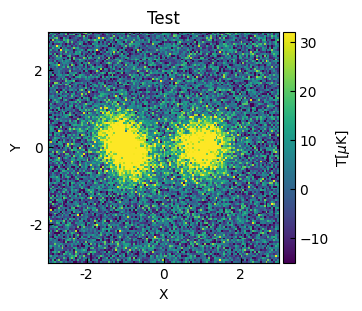

In [22]:
coord = get_coord()
kw_h1 = {
    "amplitude": 60,
    "x_mean": -1,
    "y_mean": 0,
    "x_stddev": 0.4,
    "y_stddev": 0.6,
    "theta": 0.5
}
nstd = 10
data = gen_test_data(name, *coord, kw_h1=kw_h1, noise_std=nstd)
plot_heatmap(data, title='Test')

In [23]:
model = build_model(name, init_h1=kw_h1)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=60., x_mean=-1., y_mean=0., x_stddev=0.4, y_stddev=0.6, theta=0.5)>

    [1]: <Gaussian2D(amplitude=50., x_mean=1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [2]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 x_stddev_0 ... y_stddev_1 theta_1 amplitude_2
    ----------- -------- -------- ---------- ... ---------- ------- -----------
           60.0     -1.0      0.0        0.4 ...        0.5     0.0         0.0


# without mask

In [6]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=60.57091254, x_mean=-0.99587304, y_mean=0.00567696, x_stddev=0.39740774, y_stddev=0.59490593, theta=15.74500415)>

    [1]: <Gaussian2D(amplitude=50.94602612, x_mean=0.99115609, y_mean=0.0114896, x_stddev=0.48213229, y_stddev=0.49522827, theta=-0.15858168)>

    [2]: <Const2D(amplitude=0.08163959)>
Parameters:
       amplitude_0           x_mean_0      ...     amplitude_2    
    ------------------ ------------------- ... -------------------
    60.570912544251264 -0.9958730448783242 ... 0.08163959432108142

Goodness of fit:
Chi-squared: 1443987.049
RMS residual: 10.014


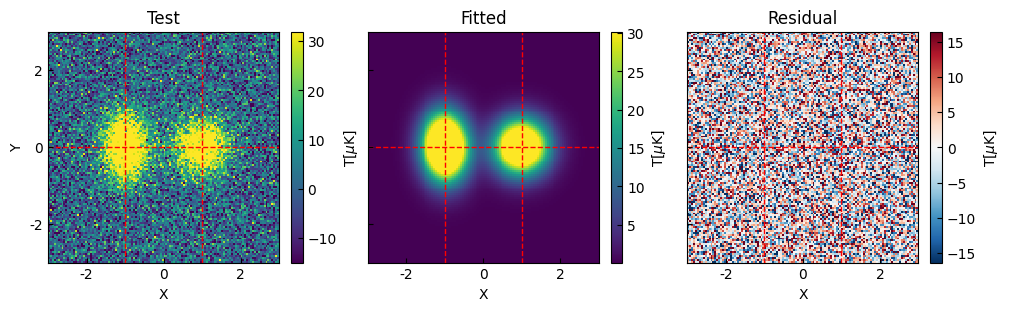

In [7]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

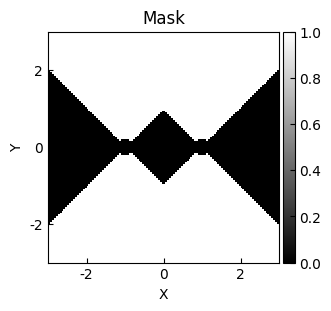

In [8]:
mask = get_mask_sector(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [9]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=61.51424994, x_mean=-1.00186063, y_mean=0.00536588, x_stddev=0.38733072, y_stddev=0.59111952, theta=0.02987616)>

    [1]: <Gaussian2D(amplitude=51.37722039, x_mean=1.01573305, y_mean=0.00562474, x_stddev=0.49701287, y_stddev=0.48464231, theta=0.54825368)>

    [2]: <Const2D(amplitude=0.19072291)>
Parameters:
       amplitude_0         x_mean_0      ...      theta_1           amplitude_2    
    ----------------- ------------------ ... ------------------ -------------------
    61.51424994385821 -1.001860634907508 ... 0.5482536836736663 0.19072291368288982

Goodness of fit:
Chi-squared: 1446162.496
RMS residual: 10.021


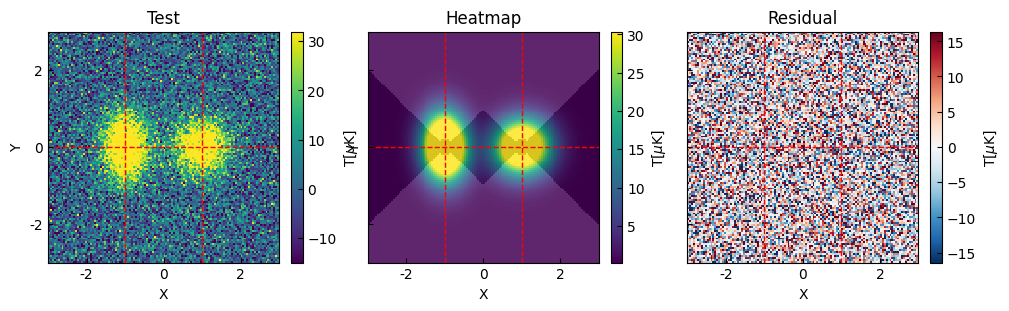

In [10]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

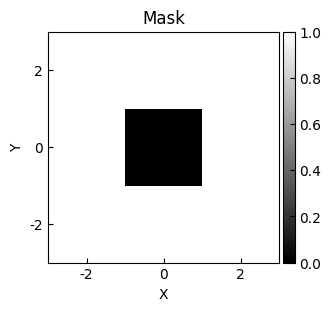

In [11]:
mask = ~get_mask_square(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [12]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=59.94777781, x_mean=-1.02090147, y_mean=0.01435186, x_stddev=0.37850742, y_stddev=0.59827361, theta=-69.09571284)>

    [1]: <Gaussian2D(amplitude=49.51805784, x_mean=1.05742856, y_mean=0.01815558, x_stddev=0.43742, y_stddev=0.49616351, theta=-0.024985)>

    [2]: <Const2D(amplitude=0.11924421)>
Parameters:
       amplitude_0          x_mean_0      ...     amplitude_2    
    ----------------- ------------------- ... -------------------
    59.94777780995587 -1.0209014742836686 ... 0.11924420849206543

Goodness of fit:
Chi-squared: 1464984.690
RMS residual: 10.086


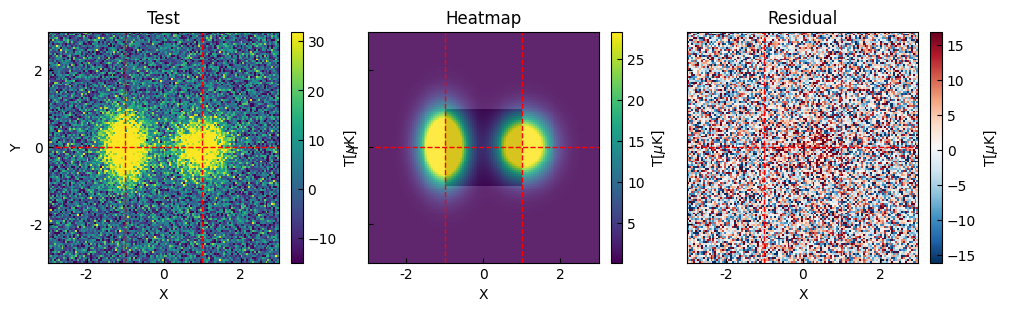

In [13]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [14]:
from mytools.plot import plot_hist

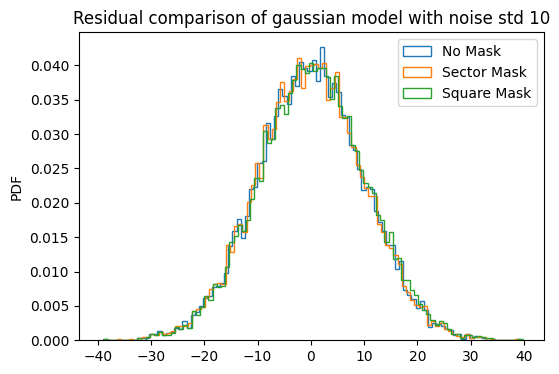

In [16]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model with noise std %d' %(name,nstd)
ax = plot_hist(res_list, label=labels, bins=100, title=title)